[206.19908462454435, 291.6714761508228, 357.2989819464925, 412.6608777192236]
4


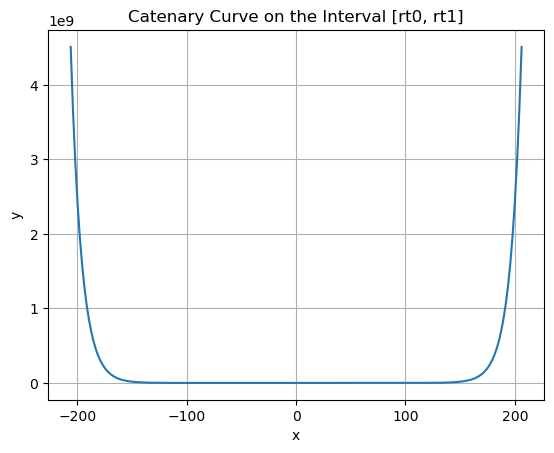

In [21]:
import numpy as np
import matplotlib.pyplot as plt

"""
Преднастройки
"""

Y_cell_size = 2*1e3 # Aperture is 1 mm
aperture = Y_cell_size # actual size in micrometers of lens
orders = 4 # the number of radial layers.
stack = 2 # N must be even., 0 - 2 - 4 - 6 - 8 - 10
LIMIT_PRODUCT = 0.2 # Limitation 200 nm. Geometry can't be larger this size.
f = 5*1e3 # focal length 5 mm
Q = 200 # curve detailing. It has almost no effect on the result
w = 0.2 # 200 nm. The width of the gap between the curves
wavelength = 4.25
k = 2 * np.pi / wavelength # wave number

def calculate_radii (D, f, wavelength, orders):
    """
    Вычисляет радиусы на поверхности линзы, на которых происходит полный фазовый сдвиг от 0 до 2Pi.

    :param D (float): Диаметр линзы.
    :param f (float): Фокусное расстояние линзы.
    :param wavelength (float): Длина волны света.
    :param orders (int): Максимальное значение n для расчета радиусов.
    :return: radii (list): Список радиусов.
    """
    radii = []
    for n in range(1, orders + 1):
        r = np.sqrt((n * wavelength)**2 + 2 * n * wavelength * f)
        if r <= D / 2:  # Проверяем, чтобы радиус не превышал радиус линзы
            radii.append(r)
        else:
            break  # Прекращаем расчет, если радиус превышает размер линзы
    return radii

rt = calculate_radii(aperture, f, wavelength, orders)
print(rt)
print(len(rt))

def catenary(x, a, x0=0):
    return a * np.cosh((x - x0) / a)

# Создаем массив значений x от rt0 до rt1
x_values = np.linspace(-rt[0], +rt[0], Q)

# Выбор параметров a, x0, y0. Эти значения можно определить экспериментально
# или исходя из требуемых граничных условий.
a = 10      # примерное значение
x0 = 0
y0 = -100     # минимальное значение y

# Вычисляем значения y для каждого x
y_values = catenary(x_values, a, x0)

# Для наглядности строим график
plt.plot(x_values, y_values)
plt.xlabel('x')
plt.ylabel('y')
plt.title('Catenary Curve on the Interval [rt0, rt1]')
plt.grid(True)
plt.show()
